<a href="https://colab.research.google.com/github/WilliamsCG57/BusinessCaseMLE_Williams/blob/main/notebooks/recompra_60d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Look · Recompra a 60 días después de la primera compra

**Objetivo de negocio:** identificar, en el momento de su primera compra, a los clientes con mayor probabilidad de volver a comprar (una **nueva orden**) en los 60 días siguientes.

**Qué hace este notebook, de principio a fin y sin pasos manuales:**

| # | Sección | Qué produce |
|---|---|---|
| 1 | Configuración | Parámetros editables (fecha de corte, ventana, tablas) |
| 2 | SQL | Tabla base en BigQuery: 1 fila por cliente, etiqueta sin fuga de información |
| 3 | Extracción y validación | DataFrame validado (unicidad, nulos, rangos) |
| 4 | Análisis exploratorio | Tasa de recompra, tiempo hasta la 2.ª compra y segmentos |
| 5 | Modelado y evaluación | Referencia (regresión logística) vs. HistGradientBoosting vs. LightGBM, separación temporal |
| 6 | Predicciones | CSV + tabla en BigQuery, sin duplicar al reejecutar |
| 7 | Pipeline automático | `run_pipeline(cfg)`: todo lo anterior en una sola llamada |

**Cómo ejecutarlo:** `Entorno de ejecución → Ejecutar todas`. Solo se edita la celda de configuración.

## 0. Librerías y autenticación

En Colab, `google-cloud-bigquery`, `scikit-learn`, `pandas` y `matplotlib` ya vienen instaladas. La autenticación abre una ventana para iniciar sesión con **tu** cuenta de Google: no se guarda ninguna credencial en el notebook ni en GitHub.

In [1]:

import os
import re
import warnings
from dataclasses import dataclass, field, replace
from datetime import datetime, timezone
from typing import Optional

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.isotonic import IsotonicRegression
from lightgbm import LGBMClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

In [2]:
try:
    from google.colab import auth
    auth.authenticate_user()
    print("Autenticado en Google Colab")
except ImportError:
    print("Fuera de Colab: ejecuta antes `gcloud auth application-default login` en tu terminal")

from google.cloud import bigquery
from google.api_core.exceptions import NotFound

Autenticado en Google Colab


## 1. Configuración

**Esta es la única celda que se edita.** Todo lo demás se calcula a partir de estos parámetros.

- `cutoff_date`: fecha de corte. `None` = última orden disponible. Para simular una corrida pasada, usa por ejemplo `"2024-06-30"`.
- `window_days`: horizonte de recompra (60 días según el negocio).
- `test_fraction`: proporción de las cohortes más recientes que se reserva para evaluar.

In [3]:
@dataclass(frozen=True)
class Config:
    # Origen y destino en BigQuery
    project_id: str = "bussiness-case-tyc"
    source_dataset: str = "bussiness_case_ecommerce"
    target_dataset: str = "williams_ccompi"
    base_table: str = "base_recompra"
    predictions_table: str = "predicciones_recompra"

    # Definición del problema
    window_days: int = 60
    cutoff_date: Optional[str] = None      # 'YYYY-MM-DD'; None = última orden disponible

    # Modelado y evaluación
    test_fraction: float = 0.20            # cohortes más recientes reservadas para test
    top_k: tuple = (0.05, 0.10, 0.20)      # % de clientes que el negocio contactaría
    random_state: int = 42

    # Salidas locales
    output_dir: str = "outputs"
    model_dir: str = "models"

    def src(self, table: str) -> str:
        return f"{self.project_id}.{self.source_dataset}.{table}"

    def dst(self, table: str) -> str:
        return f"{self.project_id}.{self.target_dataset}.{table}"


def validate_config(cfg: Config) -> None:
    # Falla rápido si un parámetro no tiene sentido
    assert cfg.window_days > 0, "window_days debe ser positivo"
    assert 0 < cfg.test_fraction < 0.5, "test_fraction debe estar entre 0 y 0.5"
    assert all(0 < k < 1 for k in cfg.top_k), "top_k debe contener proporciones entre 0 y 1"
    if cfg.cutoff_date is not None:
        pd.Timestamp(cfg.cutoff_date)  # lanza error si el formato es inválido


CFG = Config()
validate_config(CFG)
CFG

Config(project_id='bussiness-case-tyc', source_dataset='bussiness_case_ecommerce', target_dataset='williams_ccompi', base_table='base_recompra', predictions_table='predicciones_recompra', window_days=60, cutoff_date=None, test_fraction=0.2, top_k=(0.05, 0.1, 0.2), random_state=42, output_dir='outputs', model_dir='models')

In [4]:
# Variables del modelo: SOLO información conocida al momento de la primera compra.
# Se excluyen a propósito: estado final de la orden (Returned/Complete), fechas de
# envío/entrega/devolución y cualquier evento posterior a la primera compra.
# Tampoco se usan datos personales (nombre, email, dirección, coordenadas).
TARGET = "label_recompra_60d"
ID_COL = "user_id"

NUM_FEATURES = [
    "age", "days_signup_to_first_order", "first_order_dow", "first_order_month",
    "n_items", "order_value", "avg_item_price", "n_categories",
    "n_events_pre", "n_sessions_pre", "n_product_views_pre", "n_cart_pre",
]
CAT_FEATURES = ["gender", "country", "traffic_source", "main_category", "main_department"]
FEATURES = NUM_FEATURES + CAT_FEATURES

# Paleta de gráficos (categórica, validada para daltonismo)
COLORS = {"ref": "#2a78d6", "model": "#eb6834", "lgbm": "#1baf7a", "rule": "#6250d6", "accent": "#1baf7a",
          "neutral": "#8a8984", "text": "#52514e"}

## 2. SQL: tabla base del modelo

Es la misma lógica de `sql/03_tabla_base.sql`, pero **parametrizada**: la fecha de corte y la ventana entran como parámetros de consulta (`@cutoff_ts`, `@window_days`), no concatenados en el texto.

**Decisiones clave:**

| Tema | Decisión | Por qué |
|---|---|---|
| Granularidad | 1 fila por cliente | Cada CTE se agrega a su nivel (cliente u orden) **antes** de unir, así ningún join duplica filas |
| Estados | Se excluye `Cancelled` | No es una compra efectiva. `Returned` sí cuenta: la compra ocurrió y la devolución es posterior |
| Primera compra | Primera orden válida por `created_at` (desempate por `order_id`) | Definición determinística |
| Etiqueta | `COUNT(DISTINCT order_id)` posterior dentro de 60 días | Recompra a nivel **orden**: los ítems de una misma orden no cuentan |
| Fuga de información | Variables solo con datos ≤ fecha de la primera compra | El modelo debe poder usarse el mismo día de la compra |
| Censura | `ventana_completa = FALSE` si no hay 60 días de historia | No se entrenan como "no recompra"; son los clientes que se puntúan |

In [5]:
BASE_SQL = '''
WITH users_clean AS (            -- 1 fila por usuario, solo columnas no sensibles
  SELECT id AS user_id, age, gender, country, traffic_source, created_at AS signup_ts
  FROM `{src}.users`
  WHERE id IS NOT NULL
  QUALIFY ROW_NUMBER() OVER (PARTITION BY id ORDER BY created_at) = 1
),
orders_valid AS (                -- 1 fila por orden válida hasta la fecha de corte
  SELECT order_id, user_id, created_at
  FROM `{src}.orders`
  WHERE status != 'Cancelled'
    AND user_id IS NOT NULL AND created_at IS NOT NULL
    AND created_at <= @cutoff_ts
  QUALIFY ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY created_at) = 1
),
ranked AS (
  SELECT *, ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY created_at, order_id) AS rn
  FROM orders_valid
),
first_order AS (                 -- 1 fila por cliente
  SELECT user_id, order_id AS first_order_id, created_at AS first_order_ts
  FROM ranked WHERE rn = 1
),
label AS (                       -- etiqueta a nivel ORDEN
  SELECT f.user_id, COUNT(DISTINCT r.order_id) AS n_orders_60d
  FROM first_order f
  LEFT JOIN ranked r
    ON r.user_id = f.user_id AND r.rn > 1
   AND r.created_at <= TIMESTAMP_ADD(f.first_order_ts, INTERVAL @window_days DAY)
  GROUP BY f.user_id
),
first_items AS (                 -- ítems de la primera orden, agregados ANTES de unir
  SELECT i.order_id,
    COUNT(*)                   AS n_items,
    SUM(i.sale_price)          AS order_value,
    AVG(i.sale_price)          AS avg_item_price,
    COUNT(DISTINCT p.category) AS n_categories,
    APPROX_TOP_COUNT(p.category, 1)[SAFE_OFFSET(0)].value   AS main_category,
    APPROX_TOP_COUNT(p.department, 1)[SAFE_OFFSET(0)].value AS main_department
  FROM `{src}.order_items` i
  JOIN first_order f ON i.order_id = f.first_order_id
  LEFT JOIN `{src}.products` p ON i.product_id = p.id
  GROUP BY i.order_id
),
pre_events AS (                  -- navegación identificada HASTA la primera compra
  SELECT e.user_id,
    COUNT(*)                          AS n_events_pre,
    COUNT(DISTINCT e.session_id)      AS n_sessions_pre,
    COUNTIF(e.event_type = 'product') AS n_product_views_pre,
    COUNTIF(e.event_type = 'cart')    AS n_cart_pre
  FROM `{src}.events` e
  JOIN first_order f ON e.user_id = f.user_id
  WHERE e.created_at <= f.first_order_ts
  GROUP BY e.user_id
)
SELECT
  f.user_id, f.first_order_id, f.first_order_ts,
  DATE(f.first_order_ts) AS first_order_date,
  u.age, u.gender, u.country, u.traffic_source,
  DATE_DIFF(DATE(f.first_order_ts), DATE(u.signup_ts), DAY) AS days_signup_to_first_order,
  EXTRACT(DAYOFWEEK FROM f.first_order_ts) AS first_order_dow,
  EXTRACT(MONTH FROM f.first_order_ts)     AS first_order_month,
  fi.n_items, fi.order_value, fi.avg_item_price, fi.n_categories,
  fi.main_category, fi.main_department,
  IFNULL(pe.n_events_pre, 0)        AS n_events_pre,
  IFNULL(pe.n_sessions_pre, 0)      AS n_sessions_pre,
  IFNULL(pe.n_product_views_pre, 0) AS n_product_views_pre,
  IFNULL(pe.n_cart_pre, 0)          AS n_cart_pre,
  IF(l.n_orders_60d > 0, 1, 0)      AS label_recompra_60d,
  f.first_order_ts <= TIMESTAMP_SUB(@cutoff_ts, INTERVAL @window_days DAY) AS ventana_completa
FROM first_order f
JOIN users_clean u USING (user_id)
JOIN label l       USING (user_id)
LEFT JOIN first_items fi ON fi.order_id = f.first_order_id
LEFT JOIN pre_events pe  USING (user_id)
'''

# Días entre la 1.ª y la 2.ª orden válida (solo para el análisis exploratorio)
GAPS_SQL = '''
WITH orders_valid AS (
  SELECT order_id, user_id, created_at
  FROM `{src}.orders`
  WHERE status != 'Cancelled' AND user_id IS NOT NULL AND created_at IS NOT NULL
    AND created_at <= @cutoff_ts
  QUALIFY ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY created_at) = 1
),
ranked AS (
  SELECT user_id, created_at,
         ROW_NUMBER() OVER (PARTITION BY user_id ORDER BY created_at, order_id) AS rn
  FROM orders_valid
)
SELECT a.user_id,
       TIMESTAMP_DIFF(b.created_at, a.created_at, HOUR) / 24.0 AS days_to_second_order
FROM ranked a
JOIN ranked b ON a.user_id = b.user_id AND a.rn = 1 AND b.rn = 2
'''

## 3. Funciones de datos: extracción y validación

- `build_base_table` escribe la tabla con `WRITE_TRUNCATE`: reejecutar **reemplaza** la tabla, nunca agrega filas duplicadas.
- `validate_base` detiene el proceso si los datos no cumplen las reglas mínimas, en lugar de entrenar un modelo con datos rotos.

In [9]:
def get_client(cfg: Config) -> "bigquery.Client":
    return bigquery.Client(project=cfg.project_id)


def _src_prefix(cfg: Config) -> str:
    return f"{cfg.project_id}.{cfg.source_dataset}"


def _query_params(cfg: Config, cutoff_ts: pd.Timestamp) -> list:
    return [
        bigquery.ScalarQueryParameter("cutoff_ts", "TIMESTAMP", cutoff_ts.to_pydatetime()),
        bigquery.ScalarQueryParameter("window_days", "INT64", cfg.window_days),
    ]


def resolve_cutoff(client, cfg: Config) -> pd.Timestamp:
    # Fecha de corte: la indicada en la configuración (fin de ese día) o la última orden disponible
    if cfg.cutoff_date:
        return (pd.Timestamp(cfg.cutoff_date, tz="UTC")
                + pd.Timedelta(days=1) - pd.Timedelta(microseconds=1))
    sql = f"SELECT MAX(created_at) AS max_ts FROM `{cfg.src('orders')}`"
    return pd.Timestamp(client.query(sql).to_dataframe()["max_ts"].iloc[0])


def build_base_table(client, cfg: Config, cutoff_ts: pd.Timestamp) -> None:
    job_config = bigquery.QueryJobConfig(
        destination=cfg.dst(cfg.base_table),
        write_disposition="WRITE_TRUNCATE",          # idempotente: reemplaza, no agrega
        time_partitioning=bigquery.TimePartitioning(
            type_=bigquery.TimePartitioningType.MONTH, field="first_order_date"),
        clustering_fields=["user_id"],
        query_parameters=_query_params(cfg, cutoff_ts),
    )
    sql = BASE_SQL.format(src=_src_prefix(cfg))
    client.query(sql, job_config=job_config).result()
    print(f"Tabla base actualizada: {cfg.dst(cfg.base_table)} (corte {cutoff_ts:%Y-%m-%d})")


def load_base_table(client, cfg: Config) -> pd.DataFrame:
    df = client.query(f"SELECT * FROM `{cfg.dst(cfg.base_table)}`").to_dataframe()
    df["first_order_ts"] = pd.to_datetime(df["first_order_ts"], utc=True)
    df["first_order_date"] = pd.to_datetime(df["first_order_date"])
    df["ventana_completa"] = df["ventana_completa"].astype(bool)
    return df


def get_repurchase_gaps(client, cfg: Config, cutoff_ts: pd.Timestamp) -> pd.DataFrame:
    job_config = bigquery.QueryJobConfig(query_parameters=_query_params(cfg, cutoff_ts))
    sql = GAPS_SQL.format(src=_src_prefix(cfg))
    return client.query(sql, job_config=job_config).to_dataframe()


REQUIRED_COLS = [ID_COL, "first_order_ts", "first_order_date", "ventana_completa", TARGET] + FEATURES


def validate_base(df: pd.DataFrame, cfg: Config) -> dict:
    # Reglas mínimas de calidad: si alguna falla, se detiene el pipeline
    errors = []
    missing = sorted(set(REQUIRED_COLS) - set(df.columns))
    if missing:
        raise ValueError(f"Faltan columnas en la tabla base: {missing}")
    if df.empty:
        raise ValueError("La tabla base está vacía")

    if df[ID_COL].duplicated().any():
        errors.append(f"{df[ID_COL].duplicated().sum()} user_id duplicados (un join duplicó filas)")
    key_nulls = df[[ID_COL, "first_order_ts", TARGET, "ventana_completa"]].isna().sum()
    if key_nulls.any():
        errors.append(f"Nulos en campos clave: {key_nulls[key_nulls > 0].to_dict()}")
    if not set(df[TARGET].dropna().unique()) <= {0, 1}:
        errors.append("La etiqueta tiene valores distintos de 0/1")
    if (df["n_items"].fillna(0) <= 0).any():
        errors.append(f"{(df['n_items'].fillna(0) <= 0).sum()} primeras órdenes sin ítems")

    train_pool = df[df["ventana_completa"]]
    rate = train_pool[TARGET].mean() if len(train_pool) else np.nan
    if len(train_pool) < 1_000:
        errors.append(f"Muy pocos clientes con ventana completa: {len(train_pool)}")
    if not (0.005 <= rate <= 0.5):
        errors.append(f"Tasa de recompra fuera de rango esperado: {rate:.2%}")

    if errors:
        raise ValueError("Validación de la tabla base falló:\n- " + "\n- ".join(errors))

    summary = {
        "clientes": len(df),
        "con_ventana_completa": int(df["ventana_completa"].sum()),
        "a_puntuar": int((~df["ventana_completa"]).sum()),
        "tasa_recompra_60d": round(float(rate), 4),
        "rango_primera_compra": f"{df['first_order_date'].min():%Y-%m-%d} → {df['first_order_date'].max():%Y-%m-%d}",
    }
    print("Validación OK")
    return summary

In [10]:
os.makedirs(CFG.output_dir, exist_ok=True)
os.makedirs(CFG.model_dir, exist_ok=True)

client = get_client(CFG)
cutoff_ts = resolve_cutoff(client, CFG)
build_base_table(client, CFG, cutoff_ts)
df = load_base_table(client, CFG)
base_summary = validate_base(df, CFG)
pd.Series(base_summary, name="resumen")

Tabla base actualizada: bussiness-case-tyc.williams_ccompi.base_recompra (corte 2025-02-14)
Validación OK


,resumen
clientes,72027
con_ventana_completa,63538
a_puntuar,8489
tasa_recompra_60d,0.0632
rango_primera_compra,2019-01-22 → 2025-02-14


## 4. Análisis exploratorio (solo lo que orienta el modelo y el negocio)

Tres preguntas:
1. ¿Qué tan frecuente es la recompra? → define el desbalance y las métricas.
2. ¿Cuándo ocurre la segunda compra? → valida si 60 días es un horizonte razonable.
3. ¿Hay segmentos con tasas muy distintas? → orienta variables y acciones comerciales.

Solo se usan clientes con **ventana completa**, porque la etiqueta de los demás aún no se conoce.

In [11]:
def segment_rates(df_elig: pd.DataFrame, col: str, min_n: int = 200) -> pd.DataFrame:
    out = (df_elig.groupby(col, dropna=False)[TARGET]
           .agg(clientes="size", recompras="sum", tasa="mean")
           .query("clientes >= @min_n")
           .sort_values("tasa", ascending=False))
    out["lift_vs_promedio"] = out["tasa"] / df_elig[TARGET].mean()
    return out


def _style_axes(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color("#cfcdc8")
    ax.spines["bottom"].set_color("#cfcdc8")
    ax.tick_params(colors=COLORS["text"])
    ax.yaxis.label.set_color(COLORS["text"])
    ax.xaxis.label.set_color(COLORS["text"])
    ax.title.set_color("#0b0b0b")
    ax.grid(axis="x", color="#ecebe8", linewidth=0.8)
    ax.set_axisbelow(True)


def plot_segment_rates(df_elig: pd.DataFrame, cfg: Config):
    base = df_elig[TARGET].mean()
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, col, title in [
        (axes[0], "traffic_source", "Por canal de adquisición"),
        (axes[1], "main_category", "Por categoría de la 1.ª compra (top 10)"),
    ]:
        seg = segment_rates(df_elig, col).head(10).iloc[::-1]
        ax.barh(seg.index.astype(str), seg["tasa"] * 100, color=COLORS["ref"], height=0.6)
        ax.axvline(base * 100, color=COLORS["neutral"], linestyle="--", linewidth=1.5)
        ax.text(base * 100, len(seg) - 0.4, f" promedio {base:.1%}", color=COLORS["text"], fontsize=9)
        label_x = seg["tasa"].max() * 100 * 1.04   # etiquetas alineadas a la derecha de todas las barras
        for i, (v, n) in enumerate(zip(seg["tasa"], seg["clientes"])):
            ax.text(label_x, i, f"{v:.1%}  (n={n:,})", va="center", fontsize=8.5, color=COLORS["text"])
        ax.set_title(title, loc="left", fontsize=11)
        ax.set_xlabel("Tasa de recompra a 60 días (%)")
        ax.set_xlim(0, seg["tasa"].max() * 100 * 1.45)
        _style_axes(ax)
    fig.suptitle("Tasa de recompra a 60 días por segmento", x=0.01, ha="left", fontsize=13)
    fig.tight_layout()
    fig.savefig(f"{cfg.output_dir}/01_recompra_por_segmento.png", dpi=150, bbox_inches="tight")
    return fig


def plot_repurchase_gap(gaps: pd.DataFrame, cfg: Config, max_days: int = 365):
    d = gaps["days_to_second_order"]
    share_in_window = (d <= cfg.window_days).mean()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.hist(d.clip(upper=max_days), bins=np.arange(0, max_days + 10, 10),
            color=COLORS["ref"], edgecolor="white", linewidth=1)
    ax.axvline(cfg.window_days, color=COLORS["model"], linewidth=2)
    ax.text(cfg.window_days + 4, ax.get_ylim()[1] * 0.9,
            f"{cfg.window_days} días: {share_in_window:.0%} de las 2.as compras",
            color=COLORS["text"], fontsize=10)
    ax.set_title("Días entre la primera y la segunda compra", loc="left", fontsize=12)
    ax.set_xlabel(f"Días (valores > {max_days} agrupados al final)")
    ax.set_ylabel("Clientes")
    _style_axes(ax)
    ax.grid(axis="y", color="#ecebe8", linewidth=0.8)
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    fig.savefig(f"{cfg.output_dir}/02_dias_hasta_segunda_compra.png", dpi=150, bbox_inches="tight")
    return fig, share_in_window

In [12]:
df_elig = df[df["ventana_completa"]].copy()
base_rate = df_elig[TARGET].mean()
print(f"Clientes con ventana completa: {len(df_elig):,}")
print(f"Tasa de recompra a 60 días:   {base_rate:.2%}  →  1 recomprador cada {1 / base_rate:.0f} clientes")
print(f"Un modelo que dice 'nadie recompra' tendría accuracy de {1 - base_rate:.1%}: por eso NO usamos accuracy.")

gaps = get_repurchase_gaps(client, CFG, cutoff_ts)
print(f"\nClientes con 2.ª compra (cualquier plazo): {len(gaps):,}")
print(gaps["days_to_second_order"].describe(percentiles=[.25, .5, .75, .9]).round(1).to_string())

Clientes con ventana completa: 63,538
Tasa de recompra a 60 días:   6.32%  →  1 recomprador cada 16 clientes
Un modelo que dice 'nadie recompra' tendría accuracy de 93.7%: por eso NO usamos accuracy.

Clientes con 2.ª compra (cualquier plazo): 23,843
count   23,843.0000
mean       324.5000
std        346.3000
min          0.0000
25%         65.0000
50%        205.0000
75%        472.0000
90%        822.8000
max      2,118.0000


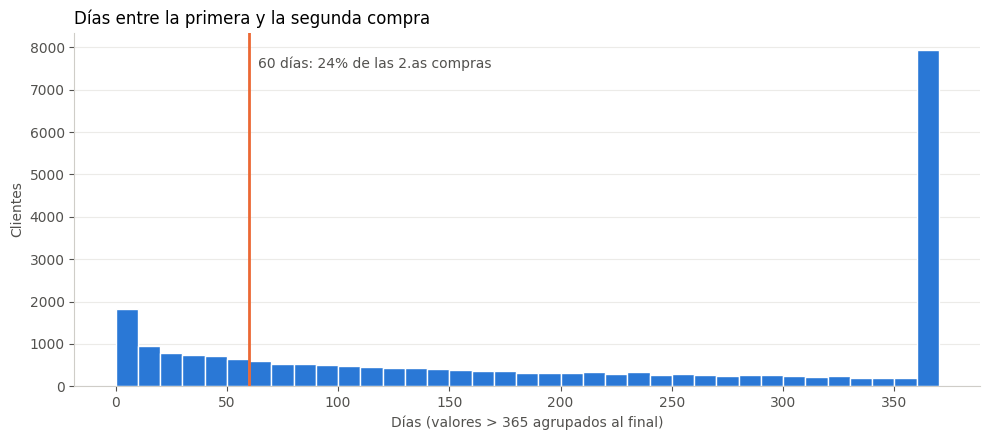

In [13]:
fig_gap, share_in_window = plot_repurchase_gap(gaps, CFG)
plt.show()

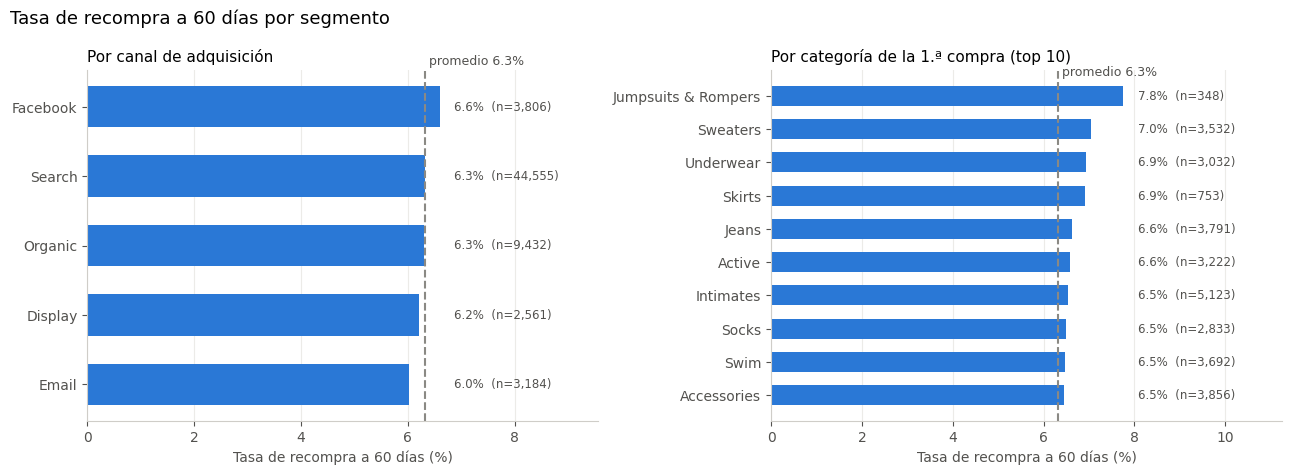

,clientes,recompras,tasa,lift_vs_promedio
traffic_source,,,,
Facebook,3806,251,0.0659,1.0429
Search,44555,2821,0.0633,1.0012
Organic,9432,595,0.0631,0.9976
Display,2561,159,0.0621,0.9818
Email,3184,192,0.0603,0.9536


In [14]:
fig_seg = plot_segment_rates(df_elig, CFG)
plt.show()
segment_rates(df_elig, "traffic_source")

In [15]:
# Variables de navegación: ¿tienen variación suficiente para aportar?
nav = ["n_sessions_pre", "n_events_pre", "n_product_views_pre", "n_cart_pre"]
df_elig[nav].describe(percentiles=[.5, .9, .99]).T.round(2)

,count,mean,std,min,50%,90%,99%,max
n_sessions_pre,"63,538.0000",1.5300,0.9000,1.0000,1.0000,3.0000,4.0000,10.0000
n_events_pre,"63,538.0000",10.1400,10.7500,1.0000,5.0000,25.0000,50.0000,114.0000
n_product_views_pre,"63,538.0000",2.8300,3.6700,0.0000,1.0000,8.0000,16.0000,34.0000
n_cart_pre,"63,538.0000",2.8100,3.6600,0.0000,1.0000,8.0000,16.0000,34.0000


**Cómo leer esta sección** (los números exactos aparecen arriba al ejecutar):
- La recompra es un evento **minoritario** → métricas principales: **PR AUC** y **precision/recall en el top-k** de clientes.
- El histograma muestra qué parte de las segundas compras ocurre dentro de los 60 días: si es una fracción relevante, el horizonte del negocio es razonable.
- Si las tasas por segmento son parecidas entre sí, la señal predictiva será débil (esperable en datos sintéticos) y conviene decirlo con honestidad.

## 5. Modelado y evaluación

**Separación temporal (no aleatoria).** Se entrena con las cohortes más antiguas y se evalúa con el `test_fraction` más reciente. Así se simula el uso real: el modelo siempre predice clientes **futuros**. Una separación aleatoria mezclaría épocas y daría métricas optimistas.

**Brecha de 60 días entre entrenamiento y prueba.** La etiqueta de un cliente se observa hasta 60 días después de su primera compra. Si un cliente de entrenamiento compró justo antes del inicio del test, su etiqueta usaría información del período de test. Por eso se descartan del entrenamiento los clientes de los 60 días previos al corte de test.

**Modelos:**
- *Azar (tasa base)*: piso mínimo. Su PR AUC es igual a la tasa de recompra.
- *Referencia — regresión logística*: modelo simple e interpretable.
- *Gradient Boosting (HistGradientBoosting de scikit-learn)*: captura relaciones no lineales e interacciones.
- *Regla simple*: ordena a los clientes solo por los días entre su registro y su primera compra (menos días → mayor probabilidad). Se incluye porque el diagnóstico de la sección 5.1 mostró que casi toda la señal está en esa variable: es la referencia más exigente para los modelos.
- *LightGBM*: boosting optimizado y estándar en la industria para datos tabulares. Se usa con *subsampling* de filas y columnas y regularización para reducir sobreajuste. Usa el mismo preprocesamiento que los demás modelos, así la comparación es justa.

**Desbalance.** No se usa `class_weight`: se mantienen las probabilidades interpretables (el negocio recibe una probabilidad), y el desbalance se aborda con métricas de ranking (PR AUC, top-k).

**Métricas:**
- **PR AUC** (principal): resume precisión vs. recall sin depender de un umbral, y es informativa con clases desbalanceadas.
- **Precision, recall, F1 y lift en el top 5/10/20 %**: traducen el modelo a la decisión real ("¿a quién contacto?").
- ROC AUC y Brier como referencia secundaria.

In [16]:
def temporal_split(df: pd.DataFrame, cfg: Config):
    elig = (df[df["ventana_completa"]]
            .sort_values(["first_order_ts", ID_COL], kind="mergesort")   # orden determinista
            .reset_index(drop=True))
    split_idx = int(len(elig) * (1 - cfg.test_fraction))
    test_start = elig.loc[split_idx, "first_order_ts"]
    train_end = test_start - pd.Timedelta(days=cfg.window_days)   # brecha anti-fuga

    train = elig[elig["first_order_ts"] < train_end]
    test = elig[elig["first_order_ts"] >= test_start]
    score = df[~df["ventana_completa"]].copy()

    assert set(train[ID_COL]).isdisjoint(test[ID_COL]), "Clientes repetidos entre train y test"
    assert set(test[ID_COL]).isdisjoint(score[ID_COL]), "Clientes repetidos entre test y scoring"
    info = {
        "train": f"{len(train):,} clientes · {train['first_order_date'].min():%Y-%m-%d} → {train['first_order_date'].max():%Y-%m-%d} · tasa {train[TARGET].mean():.2%}",
        "brecha": f"{cfg.window_days} días excluidos antes del test",
        "test": f"{len(test):,} clientes · {test['first_order_date'].min():%Y-%m-%d} → {test['first_order_date'].max():%Y-%m-%d} · tasa {test[TARGET].mean():.2%}",
        "a_puntuar": f"{len(score):,} clientes sin 60 días de historia",
    }
    return train, test, score, info


def make_preprocessor(scale_numeric: bool, num_features=None, cat_features=None) -> ColumnTransformer:
    num_features = NUM_FEATURES if num_features is None else num_features
    cat_features = CAT_FEATURES if cat_features is None else cat_features
    num_steps = [("imputar", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("escalar", StandardScaler()))
    cat_steps = [
        ("imputar", SimpleImputer(strategy="constant", fill_value="desconocido")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                                 sparse_output=False)),
    ]
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_features),
        ("cat", Pipeline(cat_steps), cat_features),
    ])


class ReglaUnaVariable(ClassifierMixin, BaseEstimator):
    # Regla simple: ordena a los clientes por UNA variable.
    # Usa regresión isotónica (monótona) para convertir la variable en una probabilidad:
    # el orden lo da la variable y la escala sale de las tasas observadas en entrenamiento.

    def __init__(self, column="days_signup_to_first_order", increasing=False):
        self.column = column
        self.increasing = increasing

    def fit(self, X, y):
        x = X[self.column].astype(float)
        self.fill_value_ = float(x.median())
        self.iso_ = IsotonicRegression(increasing=self.increasing, out_of_bounds="clip",
                                       y_min=0.0, y_max=1.0)
        self.iso_.fit(x.fillna(self.fill_value_), np.asarray(y))
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        x = X[self.column].astype(float).fillna(self.fill_value_)
        p = self.iso_.predict(x)
        # desempate dentro de cada escalón isotónico con la variable original (orden fino)
        span = float(x.max() - x.min()) or 1.0
        norm = (x.to_numpy() - x.min()) / span
        p = np.clip(p + 1e-6 * (norm if self.increasing else 1 - norm), 0, 1)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def make_models(cfg: Config) -> dict:
    return {
        "Azar (tasa base)": DummyClassifier(strategy="prior"),
        "Referencia: regresión logística": Pipeline([
            ("prep", make_preprocessor(scale_numeric=True)),
            ("clf", LogisticRegression(max_iter=2000, C=1.0)),
        ]),
        "Gradient Boosting": Pipeline([
            ("prep", make_preprocessor(scale_numeric=False)),
            ("clf", HistGradientBoostingClassifier(
                learning_rate=0.05, max_iter=400, max_leaf_nodes=31, min_samples_leaf=100,
                l2_regularization=1.0, early_stopping=True, validation_fraction=0.15,
                n_iter_no_change=30, scoring="average_precision",
                random_state=cfg.random_state)),
        ]),
        "Regla simple: días registro→compra": ReglaUnaVariable("days_signup_to_first_order"),
        "LightGBM": Pipeline([
            ("prep", make_preprocessor(scale_numeric=False)),
            ("clf", LGBMClassifier(
                n_estimators=500, learning_rate=0.03, num_leaves=31, min_child_samples=100,
                subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                random_state=cfg.random_state, n_jobs=-1, verbose=-1)),
        ]),
    }


def topk_metrics(y: np.ndarray, p: np.ndarray, k: float, seed: int = 42) -> dict:
    # Métricas si el negocio contacta solo al k% con mayor probabilidad
    n = max(1, int(round(len(y) * k)))
    tiebreak = np.random.default_rng(seed).random(len(p))   # desempate aleatorio (clave para el modelo azar)
    top = np.lexsort((tiebreak, -p))[:n]                     # ordena por p descendente, luego desempate
    tp = y[top].sum()
    precision = tp / n
    recall = tp / y.sum() if y.sum() else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return {"precision": precision, "recall": recall, "f1": f1, "lift": precision / y.mean()}


def evaluate(fitted: dict, X: pd.DataFrame, y: pd.Series, cfg: Config):
    y_arr = y.to_numpy()
    rows, probs = [], {}
    for name, model in fitted.items():
        p = model.predict_proba(X)[:, 1]
        probs[name] = p
        row = {"modelo": name,
               "PR AUC": average_precision_score(y_arr, p),
               "ROC AUC": roc_auc_score(y_arr, p) if np.unique(p).size > 1 else 0.5,
               "Brier": brier_score_loss(y_arr, p)}
        for k in cfg.top_k:
            m = topk_metrics(y_arr, p, k)
            tag = f"top{int(k * 100)}%"
            row.update({f"precision@{tag}": m["precision"], f"recall@{tag}": m["recall"],
                        f"F1@{tag}": m["f1"], f"lift@{tag}": m["lift"]})
        rows.append(row)
    return pd.DataFrame(rows).set_index("modelo"), probs


def decile_table(y: pd.Series, p: np.ndarray) -> pd.DataFrame:
    d = pd.DataFrame({"y": y.to_numpy(), "p": p})
    d["decil"] = pd.qcut(d["p"].rank(method="first", ascending=False), 10, labels=range(1, 11))
    t = d.groupby("decil", observed=True).agg(clientes=("y", "size"), recompras=("y", "sum"),
                                              prob_media=("p", "mean"))
    t["tasa_real"] = t["recompras"] / t["clientes"]
    t["lift"] = t["tasa_real"] / d["y"].mean()
    t["recompras_capturadas_acum"] = t["recompras"].cumsum() / d["y"].sum()
    return t

In [17]:
def plot_pr_curves(y: pd.Series, probs: dict, cfg: Config):
    fig, ax = plt.subplots(figsize=(7.5, 5.5))
    styles = {"Referencia: regresión logística": COLORS["ref"], "Gradient Boosting": COLORS["model"],
              "LightGBM": COLORS["lgbm"], "Regla simple: días registro→compra": COLORS["rule"]}
    y_top = y.mean()
    for name, color in styles.items():
        if name in probs:
            prec, rec, _ = precision_recall_curve(y, probs[name])
            y_top = max(y_top, prec[rec >= 0.02].max())  # ignora el ruido de los primeros clientes
            ap = average_precision_score(y, probs[name])
            ax.plot(rec, prec, color=color, linewidth=2, label=f"{name} (PR AUC {ap:.3f})")
    ax.axhline(y.mean(), color=COLORS["neutral"], linestyle="--", linewidth=1.5,
               label=f"Azar = tasa base ({y.mean():.3f})")
    ax.set_xlabel("Recall (recompradores capturados)")
    ax.set_ylabel("Precision (aciertos entre los contactados)")
    ax.set_title("Curva Precision-Recall en el período de prueba", loc="left", fontsize=12)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, min(1, y_top * 1.25))
    ax.legend(frameon=False, fontsize=9, labelcolor=COLORS["text"])
    _style_axes(ax)
    ax.grid(axis="both", color="#ecebe8", linewidth=0.8)
    fig.tight_layout()
    fig.savefig(f"{cfg.output_dir}/03_curva_precision_recall.png", dpi=150, bbox_inches="tight")
    return fig


def plot_deciles(dec: pd.DataFrame, base: float, cfg: Config):
    fig, ax = plt.subplots(figsize=(9, 4.8))
    x = dec.index.astype(int)
    ax.bar(x, dec["tasa_real"] * 100, color=COLORS["model"], width=0.65)
    ax.axhline(base * 100, color=COLORS["neutral"], linestyle="--", linewidth=1.5,
               label=f"Promedio del período de prueba ({base:.1%})")
    ax.legend(frameon=False, fontsize=9, labelcolor=COLORS["text"], loc="upper right")
    for xi, (v, lift) in zip(x, zip(dec["tasa_real"], dec["lift"])):
        ax.text(xi, v * 100, f"{v:.1%}\n×{lift:.1f}", ha="center", va="bottom", fontsize=8.5,
                color=COLORS["text"])
    top2 = dec["recompras_capturadas_acum"].iloc[1]
    ax.set_title(f"Tasa real de recompra por decil de score · el 20% con mayor score concentra "
                 f"el {top2:.0%} de las recompras", loc="left", fontsize=11)
    ax.set_xlabel("Decil de probabilidad (1 = clientes con mayor score)")
    ax.set_ylabel("Tasa real de recompra (%)")
    ax.set_xticks(x)
    ax.set_ylim(0, dec["tasa_real"].max() * 100 * 1.3)
    _style_axes(ax)
    ax.grid(axis="y", color="#ecebe8", linewidth=0.8)
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    fig.savefig(f"{cfg.output_dir}/04_tasa_por_decil.png", dpi=150, bbox_inches="tight")
    return fig


def plot_importance(model, X: pd.DataFrame, y: pd.Series, cfg: Config, n_sample: int = 6000):
    # Importancia por permutación: cuánto cae el PR AUC si se desordena cada variable
    Xs = X.sample(min(n_sample, len(X)), random_state=cfg.random_state)
    ys = y.loc[Xs.index]
    r = permutation_importance(model, Xs, ys, scoring="average_precision", n_repeats=5,
                               random_state=cfg.random_state, n_jobs=-1)
    imp = (pd.DataFrame({"variable": X.columns, "importancia": r.importances_mean,
                         "desv": r.importances_std})
           .sort_values("importancia", ascending=False).head(12).iloc[::-1])
    fig, ax = plt.subplots(figsize=(8.5, 5))
    ax.barh(imp["variable"], imp["importancia"], xerr=imp["desv"], color=COLORS["model"],
            height=0.6, error_kw={"ecolor": COLORS["neutral"], "elinewidth": 1})
    ax.axvline(0, color="#cfcdc8", linewidth=1)
    ax.set_title("Variables más influyentes (caída del PR AUC al permutarlas)", loc="left", fontsize=12)
    ax.set_xlabel("Caída del PR AUC")
    _style_axes(ax)
    fig.tight_layout()
    fig.savefig(f"{cfg.output_dir}/05_importancia_variables.png", dpi=150, bbox_inches="tight")
    return fig, imp.iloc[::-1]

In [18]:
train, test, score, split_info = temporal_split(df, CFG)
pd.Series(split_info, name="separación temporal")

,separación temporal
train,"47,119 clientes · 2019-01-22 → 2024-05-08 · tasa 4.44%"
brecha,60 días excluidos antes del test
test,"12,708 clientes · 2024-07-07 → 2024-12-16 · tasa 12.76%"
a_puntuar,"8,489 clientes sin 60 días de historia"


In [19]:
models = make_models(CFG)
fitted = {name: m.fit(train[FEATURES], train[TARGET]) for name, m in models.items()}
metrics, probs = evaluate(fitted, test[FEATURES], test[TARGET], CFG)

main_cols = ["PR AUC", "ROC AUC", "Brier"] + [c for c in metrics.columns if "top10%" in c or "top20%" in c]
metrics[main_cols]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,PR AUC,ROC AUC,Brier,precision@top10%,recall@top10%,F1@top10%,lift@top10%,precision@top20%,recall@top20%,F1@top20%,lift@top20%
modelo,,,,,,,,,,,
Azar (tasa base),0.1276,0.5000,0.1182,0.1149,0.0901,0.1010,0.9005,0.1310,0.2054,0.1600,1.0270
Referencia: regresión logística,0.2181,0.7017,0.1157,0.2455,0.1925,0.2158,1.9244,0.2427,0.3806,0.2964,1.9028
Gradient Boosting,0.2396,0.7072,0.1156,0.2777,0.2178,0.2441,2.1773,0.2384,0.3738,0.2911,1.8689
Regla simple: días registro→compra,0.2701,0.7411,0.1147,0.3210,0.2517,0.2822,2.5166,0.2919,0.4577,0.3565,2.2884
LightGBM,0.2097,0.6654,0.1154,0.2541,0.1993,0.2234,1.9923,0.2250,0.3529,0.2748,1.7641


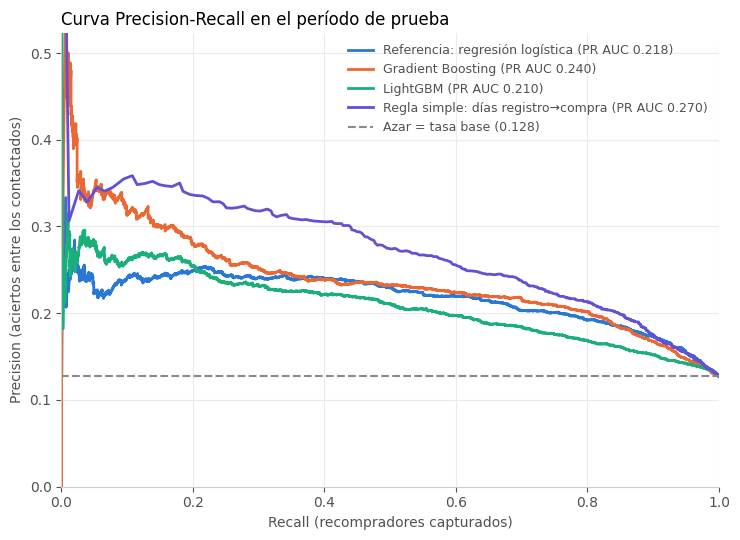

In [20]:
fig_pr = plot_pr_curves(test[TARGET], probs, CFG)
plt.show()

Mejor modelo por PR AUC en test: Regla simple: días registro→compra


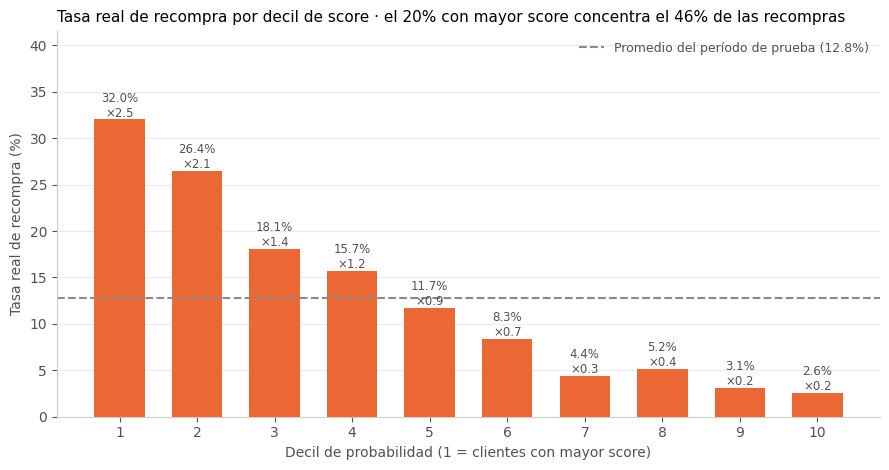

,clientes,recompras,prob_media,tasa_real,lift,recompras_capturadas_acum
decil,,,,,,
1,1271,407,0.0742,0.3202,2.5104,0.2511
2,1271,336,0.0697,0.2644,2.0725,0.4584
3,1271,230,0.0665,0.1810,1.4187,0.6002
4,1270,199,0.0589,0.1567,1.2284,0.7230
5,1271,149,0.0488,0.1172,0.9190,0.8149
6,1271,106,0.0397,0.0834,0.6538,0.8803
7,1270,56,0.0366,0.0441,0.3457,0.9149
8,1271,66,0.0303,0.0519,0.4071,0.9556
9,1271,39,0.0246,0.0307,0.2406,0.9796


In [21]:
candidates = metrics.drop(index="Azar (tasa base)")
best_name = candidates["PR AUC"].idxmax()
print(f"Mejor modelo por PR AUC en test: {best_name}")

deciles = decile_table(test[TARGET], probs[best_name])
fig_dec = plot_deciles(deciles, test[TARGET].mean(), CFG)
plt.show()
deciles

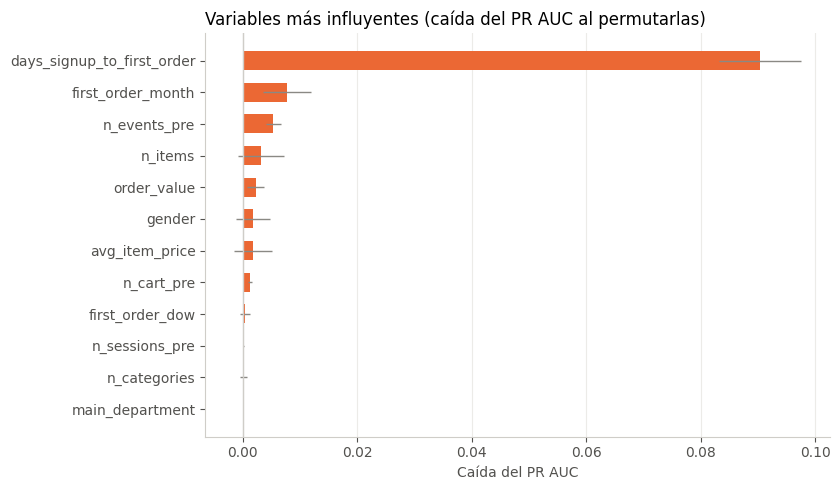

,variable,importancia,desv
1,days_signup_to_first_order,0.0904,0.0072
3,first_order_month,0.0078,0.0042
8,n_events_pre,0.0053,0.0013
4,n_items,0.0032,0.0041
5,order_value,0.0022,0.0014
12,gender,0.0017,0.0030
6,avg_item_price,0.0017,0.0033
11,n_cart_pre,0.0013,0.0004
2,first_order_dow,0.0004,0.0009
9,n_sessions_pre,0.0001,0.0000


In [22]:
# La importancia se calcula sobre el Gradient Boosting (usa todas las variables), sea o no el elegido
fig_imp, importance = plot_importance(fitted["Gradient Boosting"], test[FEATURES], test[TARGET], CFG)
plt.show()
importance

### 5.1 Diagnóstico: ¿de dónde viene la señal?

La importancia de variables muestra que `days_signup_to_first_order` domina. Antes de confiar en el modelo hay que entender por qué:
- **A.** ¿Cómo cambia la recompra según los días entre registro y primera compra?
- **B.** ¿Cómo cambia según el año de registro?
- **C.** ¿Cuánto rinde el Gradient Boosting **sin** esa variable (ablación)?

In [23]:
# A. Recompra según días entre registro y primera compra
tramos = pd.cut(df_elig["days_signup_to_first_order"], [-1, 0, 7, 30, 90, 365, 100_000],
                labels=["mismo día", "1-7", "8-30", "31-90", "91-365", ">365"])
print("A. Recompra por días entre registro y 1.ª compra")
print(df_elig.groupby(tramos, observed=True)[TARGET].agg(clientes="size", tasa="mean"), "\n")

# B. Recompra según el año de registro del cliente
signup = df_elig["first_order_ts"] - pd.to_timedelta(df_elig["days_signup_to_first_order"], unit="D")
print("B. Recompra por año de registro")
print(df_elig.groupby(signup.dt.year.rename("anio_registro"))[TARGET].agg(clientes="size", tasa="mean"), "\n")

# C. Ablación: Gradient Boosting sin la variable dominante
num_sin = [c for c in NUM_FEATURES if c != "days_signup_to_first_order"]
gb_sin = Pipeline([("prep", make_preprocessor(False, num_features=num_sin)),
                   ("clf", clone(make_models(CFG)["Gradient Boosting"].named_steps["clf"]))])
gb_sin.fit(train[num_sin + CAT_FEATURES], train[TARGET])
p_sin = gb_sin.predict_proba(test[num_sin + CAT_FEATURES])[:, 1]
pr_auc_sin = average_precision_score(test[TARGET], p_sin)

ablation = pd.Series({
    "Gradient Boosting (todas las variables)": metrics.loc["Gradient Boosting", "PR AUC"],
    "Gradient Boosting SIN days_signup_to_first_order": pr_auc_sin,
    "Regla simple (solo days_signup_to_first_order)": metrics.loc["Regla simple: días registro→compra", "PR AUC"],
    "Azar (tasa base)": test[TARGET].mean(),
}, name="PR AUC en test")
ablation.round(3)

A. Recompra por días entre registro y 1.ª compra
                            clientes   tasa
days_signup_to_first_order                 
1-7                             1160 0.1888
8-30                            3279 0.1540
31-90                           7121 0.1111
91-365                         20738 0.0695
>365                           31240 0.0340 

B. Recompra por año de registro
               clientes   tasa
anio_registro                 
2019              11321 0.0259
2020              11286 0.0278
2021              10933 0.0372
2022              11070 0.0507
2023              10710 0.0814
2024               8218 0.1912 



,PR AUC en test
Gradient Boosting (todas las variables),0.2400
Gradient Boosting SIN days_signup_to_first_order,0.1360
Regla simple (solo days_signup_to_first_order),0.2700
Azar (tasa base),0.1280


**Lectura del diagnóstico** (resultados obtenidos con corte 14-feb-2025):
- La recompra cae de forma ordenada de **18.9%** (1–7 días entre registro y compra) a **3.4%** (>365 días), y sube de **2.6%** (registrados en 2019) a **19.1%** (registrados en 2024).
- **Sin esa variable, el modelo cae a PR AUC 0.134 vs. 0.128 del azar**: el resto de variables (demografía, canal, ticket, categoría, navegación) casi no predice la recompra.
- **La regla simple (PR AUC 0.270) supera a todos los modelos (≤ 0.236).** Explicación probable: en las cohortes antiguas, los clientes tenían pocos días entre registro y compra (los datos empiezan en 2019) pero recompraban poco; los modelos aprenden esa relación mezclada con el tiempo, mientras que la regla solo usa el orden.
- **No es fuga de información** (la variable se conoce al momento de la primera compra), pero la relación parece estar ligada a cómo se generaron los datos sintéticos: probablemente las compras de cada cliente se reparten entre su registro y el final de los datos. Hay que validarla con datos reales antes de producción.
- **Lectura de negocio que se sostiene en cualquier caso:** los primeros 30 días tras el registro son la ventana crítica para activar la recompra.

**Limitaciones y mejoras**
- **Señal concentrada en una variable:** casi todo el poder predictivo viene de `days_signup_to_first_order`, y su relación con la recompra cambia en el tiempo. Riesgo de drift alto: hay que monitorear esta variable y su relación con la etiqueta.
- **La regla se descubrió mirando el test:** su ventaja es ligeramente optimista. Mejora: confirmarla con backtesting en varias fechas de corte.
- **Pocas variables de comportamiento:** solo hay una compra por cliente al momento de predecir. Mejora: atribuir eventos anónimos vía `session_id`, incorporar interacción con campañas, devoluciones previas a nivel producto y margen (`cost`).
- **Probabilidades no calibradas:** si el negocio usa la probabilidad como valor esperado, conviene calibrar (Platt/isotónica) con una ventana de validación.
- **Estacionalidad y drift:** el comportamiento cambia en el tiempo. Mejora: backtesting con varias fechas de corte (`cutoff_date`) y monitoreo de PR AUC cuando la etiqueta madura (60 días después).
- **Umbral de decisión:** se reporta top-k porque la capacidad del equipo comercial define cuántos clientes contactar. Con costos y beneficios por contacto se puede elegir el k óptimo.
- **Selección del modelo:** se elige el de mayor PR AUC en el período de prueba, así que su métrica es ligeramente optimista. Mejora: separar una ventana de validación (dentro del entrenamiento) para elegir el modelo y dejar el test solo para la estimación final.
- **Hiperparámetros:** no se hizo búsqueda exhaustiva (no se pedía). Siguiente paso: búsqueda acotada con validación temporal (`TimeSeriesSplit` por cohortes).

## 6. Predicciones y persistencia

1. Se **reentrena** el mejor modelo con todos los clientes con ventana completa (train + test), para usar la información más reciente.
2. Se puntúan los clientes **sin 60 días de historia**: son los accionables hoy.
3. Se guarda:
   - `models/modelo_recompra_<corte>.joblib`: modelo + metadatos (variables, fecha de corte, métricas).
   - `outputs/predicciones_<corte>.csv` y `outputs/muestra_predicciones.csv` (`user_id`, probabilidad).
   - Tabla `predicciones_recompra` en BigQuery, particionada por `cutoff_date`.

**Idempotencia:** antes de cargar se borran las filas de esa misma `cutoff_date`. Reejecutar el notebook con el mismo corte deja exactamente las mismas filas, sin duplicados; luego se verifica con un conteo.

In [26]:
def train_final_model(df: pd.DataFrame, model_name: str, cfg: Config):
    elig = df[df["ventana_completa"]]
    model = clone(make_models(cfg)[model_name])
    return model.fit(elig[FEATURES], elig[TARGET])


def build_predictions(model, score_df: pd.DataFrame, cutoff_ts: pd.Timestamp, model_version: str) -> pd.DataFrame:
    p = model.predict_proba(score_df[FEATURES])[:, 1]
    preds = pd.DataFrame({
        "user_id": score_df[ID_COL].astype("int64").to_numpy(),
        "first_order_date": pd.to_datetime(score_df["first_order_date"]).dt.date.to_numpy(),
        "prob_recompra_60d": np.round(p, 6),
    })
    rank_pct = preds["prob_recompra_60d"].rank(ascending=False, pct=True, method="first")
    preds["decil"] = np.ceil(rank_pct * 10).clip(1, 10).astype("int64")
    preds["segmento"] = np.select([preds["decil"] <= 1, preds["decil"] <= 3],
                                  ["Alta prioridad", "Media prioridad"], "Baja prioridad")
    preds["cutoff_date"] = cutoff_ts.date()
    preds["model_version"] = model_version
    preds["scored_at"] = pd.Timestamp.now(tz="UTC")
    return preds.sort_values("prob_recompra_60d", ascending=False).reset_index(drop=True)


def validate_predictions(preds: pd.DataFrame, score_df: pd.DataFrame) -> None:
    assert len(preds) == len(score_df), "No se puntuaron todos los clientes"
    assert preds["user_id"].is_unique, "user_id duplicados en predicciones"
    assert preds["prob_recompra_60d"].between(0, 1).all(), "Probabilidades fuera de [0, 1]"
    assert preds["prob_recompra_60d"].notna().all(), "Probabilidades nulas"
    print(f"Predicciones válidas: {len(preds):,} clientes")


def save_model(model, cfg: Config, cutoff_ts, model_name: str, metrics_row: pd.Series) -> str:
    path = f"{cfg.model_dir}/modelo_recompra_{cutoff_ts:%Y%m%d}.joblib"
    joblib.dump({
        "model": model, "model_name": model_name, "features": FEATURES,
        "num_features": NUM_FEATURES, "cat_features": CAT_FEATURES,
        "cutoff_ts": str(cutoff_ts), "window_days": cfg.window_days,
        "trained_at": datetime.now(timezone.utc).isoformat(),
        "test_metrics": metrics_row.to_dict(),
    }, path)  # mismo corte → mismo archivo (se sobrescribe)
    return path


def save_predictions_csv(preds: pd.DataFrame, cfg: Config, cutoff_ts) -> tuple:
    full_path = f"{cfg.output_dir}/predicciones_{cutoff_ts:%Y%m%d}.csv"
    sample_path = f"{cfg.output_dir}/muestra_predicciones.csv"
    preds.to_csv(full_path, index=False)
    preds[["user_id", "prob_recompra_60d"]].head(500).to_csv(sample_path, index=False)
    return full_path, sample_path


def save_predictions_bq(client, preds: pd.DataFrame, cfg: Config, cutoff_ts) -> None:
    table_id = cfg.dst(cfg.predictions_table)
    param = [bigquery.ScalarQueryParameter("d", "DATE", cutoff_ts.date())]
    try:  # borra la corrida previa con el mismo corte → reejecutar no duplica
        client.query(f"DELETE FROM `{table_id}` WHERE cutoff_date = @d",
                     job_config=bigquery.QueryJobConfig(query_parameters=param)).result()
    except NotFound:
        pass  # primera ejecución: la tabla aún no existe

    load_config = bigquery.LoadJobConfig(
        write_disposition="WRITE_APPEND",
        time_partitioning=bigquery.TimePartitioning(field="cutoff_date"),
        clustering_fields=["user_id"],
    )
    client.load_table_from_dataframe(preds, table_id, job_config=load_config).result()

    check = client.query(
        f"SELECT COUNT(*) AS n, COUNT(DISTINCT user_id) AS n_users FROM `{table_id}` WHERE cutoff_date = @d",
        job_config=bigquery.QueryJobConfig(query_parameters=param)).to_dataframe().iloc[0]
    assert check["n"] == check["n_users"] == len(preds), f"Conteo inesperado en BigQuery: {check.to_dict()}"
    print(f"{int(check['n']):,} predicciones en {table_id} (corte {cutoff_ts:%Y-%m-%d}), sin duplicados")

In [27]:
final_model = train_final_model(df, best_name, CFG)
model_version = f"{re.sub(r'[^a-z0-9]+', '_', best_name.lower()).strip('_')}_{cutoff_ts:%Y%m%d}"
preds = build_predictions(final_model, score, cutoff_ts, model_version)
validate_predictions(preds, score)

model_path = save_model(final_model, CFG, cutoff_ts, best_name, metrics.loc[best_name])
csv_path, sample_path = save_predictions_csv(preds, CFG, cutoff_ts)
save_predictions_bq(client, preds, CFG, cutoff_ts)
print(f"Modelo: {model_path}\nCSV:    {csv_path}\nMuestra:{sample_path}")

preds.groupby("segmento").agg(clientes=("user_id", "size"),
                              prob_media=("prob_recompra_60d", "mean")).sort_values("prob_media", ascending=False)

Predicciones válidas: 8,489 clientes
8,489 predicciones en bussiness-case-tyc.williams_ccompi.predicciones_recompra (corte 2025-02-14), sin duplicados
Modelo: models/modelo_recompra_20250214.joblib
CSV:    outputs/predicciones_20250214.csv
Muestra:outputs/muestra_predicciones.csv


,clientes,prob_media
segmento,,
Alta prioridad,848,0.1908
Media prioridad,1698,0.1899
Baja prioridad,5943,0.0819


## 7. Pipeline automático de punta a punta

`run_pipeline(cfg)` encadena todas las funciones anteriores **sin pasos manuales**. Es la función que ejecutaría un job programado (en AWS, por ejemplo, un paso de SageMaker Pipelines disparado por EventBridge).

Para otra fecha de corte basta con: `run_pipeline(replace(CFG, cutoff_date="2024-06-30"))`.

In [28]:
def run_pipeline(cfg: Config, client=None, save_to_bq: bool = True) -> dict:
    validate_config(cfg)
    os.makedirs(cfg.output_dir, exist_ok=True)
    os.makedirs(cfg.model_dir, exist_ok=True)
    client = client or get_client(cfg)

    # 1. Datos
    cutoff_ts = resolve_cutoff(client, cfg)
    build_base_table(client, cfg, cutoff_ts)
    df = load_base_table(client, cfg)
    summary = validate_base(df, cfg)

    # 2. Modelado y evaluación temporal
    train, test, score, split_info = temporal_split(df, cfg)
    fitted = {n: m.fit(train[FEATURES], train[TARGET]) for n, m in make_models(cfg).items()}
    metrics, _ = evaluate(fitted, test[FEATURES], test[TARGET], cfg)
    best = metrics.drop(index="Azar (tasa base)")["PR AUC"].idxmax()

    # 3. Modelo final y predicciones
    final = train_final_model(df, best, cfg)
    version = f"{re.sub(r'[^a-z0-9]+', '_', best.lower()).strip('_')}_{cutoff_ts:%Y%m%d}"
    preds = build_predictions(final, score, cutoff_ts, version)
    validate_predictions(preds, score)

    # 4. Persistencia idempotente
    model_path = save_model(final, cfg, cutoff_ts, best, metrics.loc[best])
    csv_path, _ = save_predictions_csv(preds, cfg, cutoff_ts)
    if save_to_bq:
        save_predictions_bq(client, preds, cfg, cutoff_ts)

    return {"cutoff_ts": cutoff_ts, "summary": summary, "split": split_info,
            "metrics": metrics, "best_model": best, "n_predictions": len(preds),
            "model_path": model_path, "csv_path": csv_path}

In [29]:
# Reejecución completa: debe dar el mismo número de predicciones y no duplicar filas en BigQuery
result = run_pipeline(CFG, client=client)
print(f"\nCorte: {result['cutoff_ts']:%Y-%m-%d} · mejor modelo: {result['best_model']} · "
      f"predicciones: {result['n_predictions']:,}")
assert result["n_predictions"] == len(preds), "La reejecución cambió el número de predicciones"
print("Reejecución idempotente verificada")

Tabla base actualizada: bussiness-case-tyc.williams_ccompi.base_recompra (corte 2025-02-14)
Validación OK


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Predicciones válidas: 8,489 clientes
8,489 predicciones en bussiness-case-tyc.williams_ccompi.predicciones_recompra (corte 2025-02-14), sin duplicados

Corte: 2025-02-14 · mejor modelo: Regla simple: días registro→compra · predicciones: 8,489
Reejecución idempotente verificada


## 8. Resumen para negocio

In [30]:
best = metrics.loc[best_name]
base_test = test[TARGET].mean()
top10 = best["precision@top10%"]
print(f"• Históricamente, el {base_rate:.1%} de los clientes vuelve a comprar dentro de 60 días.")
print(f"• La recompra pasó de {train[TARGET].mean():.1%} (entrenamiento) a {base_test:.1%} (cohortes recientes): "
      f"el modelo ordena bien, pero debe reentrenarse con frecuencia.")
print(f"• El {share_in_window:.0%} de las segundas compras ocurre dentro de los primeros {CFG.window_days} días.")
print(f"• Modelo elegido: {best_name}. PR AUC {best['PR AUC']:.3f} vs. {base_test:.3f} al azar.")
print(f"• Casi toda la señal está en los días entre registro y primera compra: sin esa variable, "
      f"el Gradient Boosting cae a PR AUC {pr_auc_sin:.3f}.")
print(f"• Si se contacta al 10% con mayor score, {top10:.1%} recompra (×{best['lift@top10%']:.1f} vs. el promedio) "
      f"y se captura el {best['recall@top10%']:.0%} de los recompradores.")
print(f"• Con el 20%: se captura el {best['recall@top20%']:.0%} de los recompradores.")
print(f"• Hoy hay {len(preds):,} clientes recientes puntuados: "
      f"{(preds['segmento'] == 'Alta prioridad').sum():,} en alta prioridad para la próxima campaña.")

• Históricamente, el 6.3% de los clientes vuelve a comprar dentro de 60 días.
• La recompra pasó de 4.4% (entrenamiento) a 12.8% (cohortes recientes): el modelo ordena bien, pero debe reentrenarse con frecuencia.
• El 24% de las segundas compras ocurre dentro de los primeros 60 días.
• Modelo elegido: Regla simple: días registro→compra. PR AUC 0.270 vs. 0.128 al azar.
• Casi toda la señal está en los días entre registro y primera compra: sin esa variable, el Gradient Boosting cae a PR AUC 0.136.
• Si se contacta al 10% con mayor score, 32.1% recompra (×2.5 vs. el promedio) y se captura el 25% de los recompradores.
• Con el 20%: se captura el 46% de los recompradores.
• Hoy hay 8,489 clientes recientes puntuados: 848 en alta prioridad para la próxima campaña.
